# Демонстрации к лекции 8: ограничения-равенства

Ноутбук — для самостоятельной проверки после пары: всё, что на лекции было формулой или картинкой, здесь считается кодом, а числа конспекта печатаются рядом с ожидаемыми. Читается сверху вниз; каждая часть начинается с «что проверяем и что должны увидеть».

- **(0)** числа введения: две точки Лагранжа на окружности и натяжения стержней цепи из IPOPT;
- **(a)** условие первого порядка (раздел 2): система $\nabla_xL=0$, $g=0$ на окружности, два решения, касательное пространство и проверка $\nabla f^\top Z=0$;
- **(b)** множитель, которого нет (раздел 3): клюв — $\hat\lambda\to\infty$; повторённое ограничение — $\operatorname{rank}J<m$ и семейство множителей;
- **(c)** цепь на стержнях (раздел 5): IPOPT, `lam_g`, три проверки — стационарность, LICQ, редуцированный гессиан, — и постоянная горизонтальная составляющая натяжения;
- **(e)** подробности: цена доходности портфеля, цена длины цепи, лог IPOPT (`inf_pr`, `inf_du`) из хорошего и плохого старта, знак `lam_g`.

Конспект: [`lecture08.md`](lecture08.md). Запуск: `uv run --group casadi jupyter lab` в корне репозитория; в Colab первая ячейка ставит CasADi сама.

In [1]:
%matplotlib inline

import importlib.util, subprocess, sys
if importlib.util.find_spec("casadi") is None:          # Colab: поставить CasADi один раз
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "casadi"], check=True)

import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import null_space
from scipy.optimize import fsolve

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
GRAY, INK = "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- задачи (те же, что в demo08 / l8helpers.py)
A_CIRCLE = np.array([2.0, 1.0])            # введение и §2.1: ближайшая к a точка единичной окружности


def circle_system(z, a=A_CIRCLE):
    """Система условий первого порядка для min 1/2|x - a|^2 при 1/2(|x|^2 - 1) = 0: (x - a) - lam x = 0, g = 0."""
    x, lam = z[:2], z[2]
    return np.r_[(x - a) - lam * x, 0.5 * (x @ x - 1)]


def circle_points(a=A_CIRCLE):
    """Оба решения системы: (x, lam) ближней и дальней точки."""
    na = np.linalg.norm(a)
    return (a / na, 1 - na), (-a / na, 1 + na)


def cusp_grad(x1):
    """Клюв g = x2^3 - x1^2 = 0, f = x2: в точке кривой x2 = x1^(2/3) возвращает grad g, оценку lambda, угол к grad f (град)."""
    x2 = x1 ** (2 / 3)
    gf, gg = np.array([0.0, 1.0]), np.array([-2 * x1, 3 * x2 ** 2])
    lam = gf @ gg / (gg @ gg)                                  # наименьшие квадраты для grad f = lam grad g
    ang = np.degrees(np.arccos(gf @ gg / np.linalg.norm(gg)))
    return gg, lam, ang


def rod_chain(N=40, L_total=5.0, g_acc=9.81):
    """Цепь на стержнях: N грузов между (-2, 1) и (2, 1), N + 1 стержней длины L_total / (N + 1), f = w sum z.
    Возвращает словарь с символьными v, f, g (CasADi), весом w, длиной стержня ell и функцией старта."""
    m = 4.0 / N; w = m * g_acc; ell = L_total / (N + 1)
    v = ca.SX.sym("v", 2 * N)
    y = ca.vertcat(-2.0, v[:N], 2.0); z = ca.vertcat(1.0, v[N:], 1.0)
    f = w * ca.sum1(z[1:-1])
    g = ca.vertcat(*[(y[j + 1] - y[j]) ** 2 + (z[j + 1] - z[j]) ** 2 - ell ** 2 for j in range(N + 1)])
    t = np.linspace(-2, 2, N + 2)[1:-1]
    return dict(v=v, f=f, g=g, w=w, ell=ell, N=N, v0=np.r_[t, np.zeros(N)])


def solve_rod_chain(ch, v0=None, tol=1e-10):
    """IPOPT для цепи на стержнях. Возвращает (v*, lam* в нашем знаке L = f - lam^T g, stats)."""
    solver = ca.nlpsol("s", "ipopt", {"x": ch["v"], "f": ch["f"], "g": ch["g"]},
                       {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes", "ipopt.tol": tol})
    sol = solver(x0=ch["v0"] if v0 is None else v0, lbg=0, ubg=0)
    return np.array(sol["x"]).ravel(), -np.array(sol["lam_g"]).ravel(), solver.stats()   # IPOPT: L = f + lam_g^T g


def chain_xy(ch, v):
    N = ch["N"]
    return np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]


def chain_checks(ch, v, lam):
    """Три проверки §5.1: невязка стационарности, ранг J, собственные числа редуцированного гессиана; натяжения."""
    J = ca.Function("J", [ch["v"]], [ca.jacobian(ch["g"], ch["v"])])(v).full()
    gf = ca.Function("gf", [ch["v"]], [ca.gradient(ch["f"], ch["v"])])(v).full().ravel()
    lsym = ca.SX.sym("l", ch["N"] + 1)
    H = ca.Function("H", [ch["v"], lsym], [ca.hessian(ch["f"] - ca.dot(lsym, ch["g"]), ch["v"])[0]])(v, lam).full()
    Z = null_space(J)
    y, z = chain_xy(ch, v)
    F = 2 * np.abs(lam) * ch["ell"]                            # натяжение стержня
    Fh = 2 * lam * np.diff(y)                                  # горизонтальная составляющая
    return dict(res=np.linalg.norm(gf - J.T @ lam), rank=np.linalg.matrix_rank(J), eig=np.linalg.eigvalsh(Z.T @ H @ Z),
                Z=Z, F=F, Fh=Fh, Fv=2 * lam * np.diff(z))


PF_R = np.array([0.04, 0.08, 0.11, 0.15])                              # портфель Л3: доходности
PF_VOL = np.array([0.05, 0.12, 0.18, 0.30])
PF_CORR = np.array([[1, 0.2, 0.1, 0.0], [0.2, 1, 0.5, 0.3], [0.1, 0.5, 1, 0.4], [0.0, 0.3, 0.4, 1.0]])
PF_SIGMA = np.outer(PF_VOL, PF_VOL) * PF_CORR


def portfolio_eq(rho):
    """min 1/2 x'Sx при 1'x = 1, r'x = rho — только равенства: система ККТ линейна. Возвращает (x, f*, lam)."""
    Aeq = np.c_[np.ones(4), PF_R].T
    K = np.block([[PF_SIGMA, -Aeq.T], [Aeq, np.zeros((2, 2))]])
    sol = np.linalg.solve(K, np.r_[np.zeros(4), 1.0, rho])
    return sol[:4], 0.5 * sol[:4] @ PF_SIGMA @ sol[:4], sol[4:]


def level_circles(ax, a, levels, color=BLUE, lw=1.2, alpha=0.8):
    """Линии уровня f = 1/2 |x - a|^2 — окружности вокруг a радиуса sqrt(2 f)."""
    th = np.linspace(0, 2 * np.pi, 400)
    for f in levels:
        r = np.sqrt(2 * f)
        ax.plot(a[0] + r * np.cos(th), a[1] + r * np.sin(th), color=color, lw=lw, alpha=alpha)


def unit_circle(ax, color=INK, lw=2.2):
    th = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), color=color, lw=lw)

## (0) Числа введения

**Что проверяем.** Два числа из введения: система условий первого порядка для ближайшей к $a=(2,1)$ точки единичной окружности имеет два решения, $\lambda=1\mp\sqrt5$; цепь из $40$ грузов на стержнях IPOPT решает за $13$ итераций, и множители — это натяжения: $23.9$ Н на концах, $13.6$ Н в середине, горизонтальная составляющая $13.6$ Н везде.

In [2]:
for z0 in ([1, 0.5, 0], [-1, -0.5, 0]):                               # два старта для fsolve: справа и слева
    z = fsolve(circle_system, z0, xtol=1e-14)                          # решаем (x - a) - lam x = 0, 1/2(|x|^2 - 1) = 0
    print(f"x = ({z[0]:+.3f}, {z[1]:+.3f}),  lambda = {z[2]:+.3f},  f = {0.5 * np.sum((z[:2] - A_CIRCLE) ** 2):.3f}")
print(f"в конспекте: lambda = 1 - sqrt5 = {1 - np.sqrt(5):+.3f} (минимум) и 1 + sqrt5 = {1 + np.sqrt(5):+.3f} (максимум)")

x = (+0.894, +0.447),  lambda = -1.236,  f = 0.764
x = (-0.894, -0.447),  lambda = +3.236,  f = 5.236
в конспекте: lambda = 1 - sqrt5 = -1.236 (минимум) и 1 + sqrt5 = +3.236 (максимум)


In [3]:
ch = rod_chain()                                                       # N = 40 грузов, 41 стержень длины 5/41, f = w sum z
v, lam, st = solve_rod_chain(ch)                                       # IPOPT; lam — в нашем знаке L = f - lam^T g
chk = chain_checks(ch, v, lam)                                         # натяжения F_j = 2|lam_j| ell и их составляющие
print(f"IPOPT: {st['iter_count']} итераций (в конспекте 13), f* = {ch['w'] * chain_xy(ch, v)[1][1:-1].sum():.3f} Дж (5.756)")
print(f"натяжение: концы {chk['F'][0]:.1f} Н, середина {chk['F'][20]:.1f} Н (в конспекте 23.9 и 13.6)")
print(f"горизонтальная составляющая: от {np.abs(chk['Fh']).min():.4f} до {np.abs(chk['Fh']).max():.4f} Н — одна и та же во всех 41 стержнях")

IPOPT: 13 итераций (в конспекте 13), f* = 5.756 Дж (5.756)
натяжение: концы 23.9 Н, середина 13.6 Н (в конспекте 23.9 и 13.6)
горизонтальная составляющая: от 13.6007 до 13.6007 Н — одна и та же во всех 41 стержнях


## (a) Условие первого порядка на окружности (раздел 2)

**Что проверяем.** Система $\nabla_xL=0$, $g=0$ — три уравнения на $(x_1,x_2,\lambda)$ — имеет два решения: ближнюю и дальнюю точки окружности. В обеих $\nabla f=\lambda\nabla g$ с точностью машинного нуля, а в любой другой точке окружности у $\nabla f$ есть ненулевая касательная часть $Z^\top\nabla f$, где $Z$ — базис касательного пространства $\ker J$.

In [4]:
a = A_CIRCLE                                                           # a = (2, 1)
grad_f = lambda x: x - a                                               # grad f для f = 1/2 |x - a|^2
grad_g = lambda x: x                                                   # grad g для g = 1/2 (|x|^2 - 1)
sols = [fsolve(circle_system, z0, xtol=1e-14) for z0 in ([1, 0.5, 0], [-1, -0.5, 0])]
for z in sols:
    x, lam = z[:2], z[2]
    print(f"x = ({x[0]:+.4f}, {x[1]:+.4f}), lambda = {lam:+.4f}:  |grad f - lambda grad g| = {np.linalg.norm(grad_f(x) - lam * grad_g(x)):.1e}")

x = (+0.8944, +0.4472), lambda = -1.2361:  |grad f - lambda grad g| = 1.1e-16
x = (-0.8944, -0.4472), lambda = +3.2361:  |grad f - lambda grad g| = 0.0e+00


In [5]:
def tangent_part(x):
    """Касательная часть grad f: Z^T grad f, где Z — базис ker J (здесь J = grad g^T — одна строка)."""
    J = grad_g(x).reshape(1, -1)                                       # якобиан 1 x 2
    Z = null_space(J)                                                  # 2 x 1 — базис касательного пространства
    return (Z.T @ grad_f(x)).item()

for name, x in (("минимум", sols[0][:2]), ("максимум", sols[1][:2]), ("точка (0.5, 0.866)", np.array([0.5, np.sqrt(3) / 2]))):
    print(f"{name:18s}: касательная часть grad f = {tangent_part(x):+.4f}")

минимум           : касательная часть grad f = +0.0000
максимум          : касательная часть grad f = +0.0000
точка (0.5, 0.866): касательная часть grad f = +1.2321


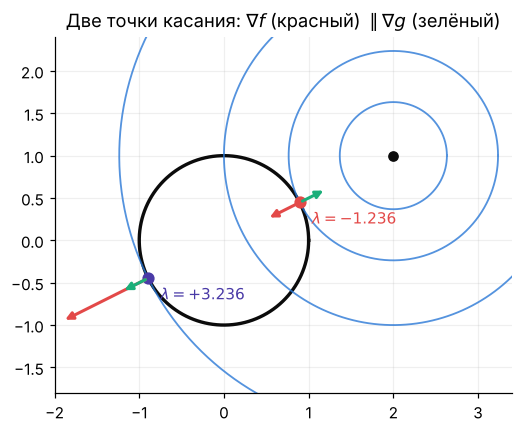

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.2))
unit_circle(ax)                                                         # g = 0
level_circles(ax, a, [0.5 * np.sum((z[:2] - a) ** 2) for z in sols] + [0.2, 2.0], color=BLUE)   # линии уровня f, две — касаются
for z, col in zip(sols, (RED, VIOLET)):
    x = z[:2]
    ax.annotate("", x + 0.35 * grad_f(x), x, arrowprops=dict(arrowstyle="-|>", color=RED, lw=2))       # grad f
    ax.annotate("", x + 0.35 * grad_g(x), x, arrowprops=dict(arrowstyle="-|>", color=AQUA, lw=2))      # grad g
    ax.plot(*x, "o", color=col, ms=7); ax.annotate(f"$\\lambda={z[2]:+.3f}$", x, (8, -14), textcoords="offset points", color=col)
ax.plot(*a, "o", color=INK); ax.set_aspect("equal"); ax.set_xlim(-2, 3.4); ax.set_ylim(-1.8, 2.4)
ax.set_title("Две точки касания: $\\nabla f$ (красный) $\\parallel\\nabla g$ (зелёный)"); plt.show()

## (b) Множитель, которого нет (раздел 3)

**Что проверяем.** Клюв $g=x_2^3-x_1^2$, $f=x_2$: минимум в $(0,0)$, но $\nabla g(0,0)=0$. Вдоль кривой к клюву «лучший» множитель $\hat\lambda=\nabla f^\top\nabla g/\lVert\nabla g\rVert^2$ растёт как $x_1^{-2/3}$, а невязка $\lVert\nabla f-\hat\lambda\nabla g\rVert$ стремится к $1$: уравновесить $\nabla f$ нечем. Второй случай — ограничение, записанное дважды: $\operatorname{rank}J=1<2$, множители не единственны, IPOPT возвращает один из них.

In [7]:
print(f"{'x1':>8s} {'|grad g|':>10s} {'lambda^':>9s} {'невязка':>9s} {'угол':>7s}")
for x1 in (0.5, 0.1, 0.01, 0.001, 1e-4):
    gg, lam_hat, ang = cusp_grad(x1)                                    # grad g, оценка lambda, угол к grad f
    res = np.linalg.norm(np.array([0.0, 1.0]) - lam_hat * gg)          # |grad f - lambda^ grad g|
    print(f"{x1:8.0e} {np.linalg.norm(gg):10.4f} {lam_hat:9.2f} {res:9.4f} {ang:6.1f}°")
print("в конспекте: при x1 = 0.1, 0.01, 0.001 — lambda^ = 2.3, 14.6, 73 и угол 55°, 72°, 81°")

      x1   |grad g|   lambda^   невязка    угол
   5e-01     1.5548      0.49    0.6432   40.0°
   1e-01     0.2437      2.34    0.8207   55.2°
   1e-02     0.0210     14.63    0.9515   72.1°
   1e-03     0.0020     73.35    0.9889   81.5°
   1e-04     0.0002    346.44    0.9976   86.0°
в конспекте: при x1 = 0.1, 0.01, 0.001 — lambda^ = 2.3, 14.6, 73 и угол 55°, 72°, 81°


**Повторённое ограничение.** $\min\tfrac12\lVert x-a\rVert^2$ при $x_1+x_2=1$: решение $x^\ast=(1,0)$, $\lambda=-1$ (в нашем знаке). Запишем то же ограничение дважды: $J=\begin{pmatrix}1&1\\1&1\end{pmatrix}$ ранга $1$, и любые $\lambda_1+\lambda_2=-1$ решают $\nabla f=J^\top\lambda$. IPOPT не ломается — он возвращает $\lambda_1=\lambda_2$ (а в `lam_g` знак противоположный нашему).

In [8]:
x = ca.SX.sym("x", 2)
f = 0.5 * ca.sumsqr(x - ca.DM([2, 1]))                                 # f = 1/2 |x - a|^2
g1 = x[0] + x[1] - 1                                                   # одно ограничение
for name, g in (("одно ограничение", g1), ("то же дважды", ca.vertcat(g1, g1)), ("g и 2g", ca.vertcat(g1, 2 * g1))):
    s = ca.nlpsol("s", "ipopt", {"x": x, "f": f, "g": g}, {"ipopt.print_level": 0, "print_time": 0, "ipopt.sb": "yes"})
    sol = s(x0=[0, 0], lbg=0, ubg=0)                                   # равенство: lbg = ubg = 0
    J = ca.Function("J", [x], [ca.jacobian(g, x)])(sol["x"]).full()    # якобиан в решении
    print(f"{name:18s}: x* = {np.array(sol['x']).ravel()}, rank J = {np.linalg.matrix_rank(J)}, lam (наш знак) = {-np.array(sol['lam_g']).ravel()}")

одно ограничение  : x* = [1. 0.], rank J = 1, lam (наш знак) = [-1.]
то же дважды      : x* = [1.00000000e+00 1.40585332e-09], rank J = 1, lam (наш знак) = [-0.5 -0.5]
g и 2g            : x* = [1.00000000e+00 5.62341321e-10], rank J = 1, lam (наш знак) = [-0.19999998 -0.40000001]


## (c) Цепь на стержнях в IPOPT (раздел 5)

**Что проверяем.** $80$ координат, $41$ равенство. IPOPT из опущенной прямой $z=0$ — $13$ итераций. Три проверки таблицы раздела 4: невязка стационарности $\lVert\nabla f-J^\top\lambda\rVert\approx10^{-12}$, $\operatorname{rank}J=41$ (LICQ), редуцированный гессиан $39\times39$ положительно определён. Множители — натяжения; горизонтальная составляющая $2\lambda_j\Delta y_j$ одинакова во всех стержнях. **Предскажите до запуска:** сколько ньютонов в вертикальных составляющих на двух опорах вместе? (Вес цепи — $40\cdot0.981=39.24$ Н.)

In [9]:
ch = rod_chain()                                                       # задача: v = (y_1..y_40, z_1..z_40), g_j = |p_{j+1} - p_j|^2 - ell^2
v, lam, st = solve_rod_chain(ch)                                       # IPOPT из прямой z = 0
chk = chain_checks(ch, v, lam)                                         # невязка, ранг J, редуцированный гессиан, силы
print(f"итераций {st['iter_count']} (в конспекте 13);  |grad f - J^T lam| = {chk['res']:.1e}")
print(f"rank J = {chk['rank']} из 41 — LICQ выполнено;  Z: {chk['Z'].shape} — базис касательного пространства размерности 80 - 41 = 39")
print(f"редуцированный гессиан Z^T H_L Z: собственные числа от {chk['eig'].min():.2f} до {chk['eig'].max():.1f} — все > 0, строгий минимум")
print(f"множители: концы {lam[0]:.2f}, середина {lam[20]:.2f} (в конспекте -97.9 и -55.8)")

итераций 13 (в конспекте 13);  |grad f - J^T lam| = 1.2e-13
rank J = 41 из 41 — LICQ выполнено;  Z: (80, 39) — базис касательного пространства размерности 80 - 41 = 39
редуцированный гессиан Z^T H_L Z: собственные числа от 2.17 до 680.6 — все > 0, строгий минимум
множители: концы -97.88, середина -55.76 (в конспекте -97.9 и -55.8)


горизонтальная составляющая 2 lam_j dy_j: -13.6007 … -13.6007 Н — одинакова во всех стержнях
вертикальные на опорах: 19.62 + 19.62 = 39.24 Н = вес цепи 39.24 Н


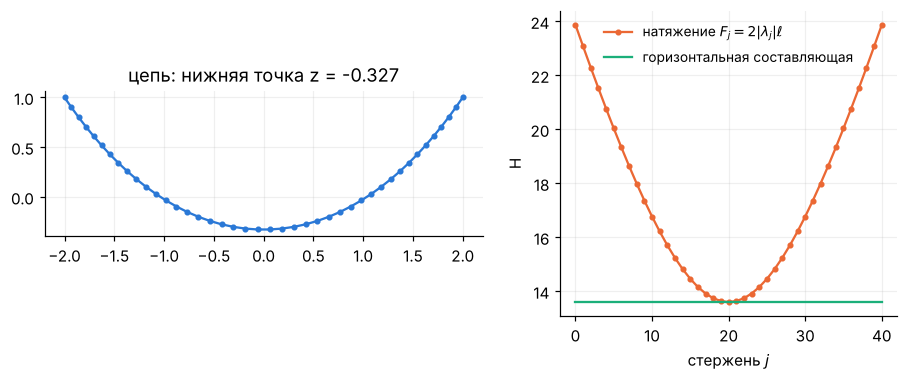

In [10]:
Fh, Fv = chk["Fh"], chk["Fv"]                                          # горизонтальная и вертикальная составляющие силы стержня j
print(f"горизонтальная составляющая 2 lam_j dy_j: {Fh.min():.4f} … {Fh.max():.4f} Н — одинакова во всех стержнях")
print(f"вертикальные на опорах: {abs(Fv[0]):.2f} + {abs(Fv[-1]):.2f} = {abs(Fv[0]) + abs(Fv[-1]):.2f} Н = вес цепи {ch['w'] * ch['N']:.2f} Н")
y, z = chain_xy(ch, v)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
axes[0].plot(y, z, "o-", color=BLUE, ms=3); axes[0].set_aspect("equal"); axes[0].set_title(f"цепь: нижняя точка z = {z.min():.3f}")
axes[1].plot(chk["F"], "o-", color=ORANGE, ms=3, label="натяжение $F_j=2|\\lambda_j|\\ell$")
axes[1].plot(np.abs(Fh), color=AQUA, label="горизонтальная составляющая"); axes[1].set_xlabel("стержень $j$"); axes[1].set_ylabel("Н"); axes[1].legend(fontsize=9)
plt.show()

## (e) Подробности

**Цена доходности.** Портфель с двумя равенствами при цели $\rho=10\,\%$: $\lambda_\rho=0.257$ совпадает с численной производной $f^\ast(\rho)$. При $\rho>10.64\,\%$ доля первого актива становится отрицательной — тогда в задаче лекции 3 включается ограничение $x\ge0$, и цена доходности меняется ($0.47$ при $12\,\%$).

In [11]:
x, f_star, lam_pf = portfolio_eq(0.10)                                 # система ККТ линейна: решается np.linalg.solve
d = 1e-5
fd = (portfolio_eq(0.10 + d)[1] - portfolio_eq(0.10 - d)[1]) / (2 * d)  # центральная разность по rho
print(f"x* = {np.round(x, 4)}, f* = {f_star:.6f}, lambda_rho = {lam_pf[1]:.4f}, df*/drho (разность) = {fd:.4f}")
rhos = np.linspace(0.06, 0.14, 801)
xa = np.array([portfolio_eq(r)[0][0] for r in rhos])                   # доля первого актива как функция цели
print(f"x_1 = 0 при rho = {rhos[np.argmin(np.abs(xa))] * 100:.2f} %")

x* = [0.0946 0.3822 0.3209 0.2023], f* = 0.008204, lambda_rho = 0.2571, df*/drho (разность) = 0.2571
x_1 = 0 при rho = 10.64 %


**Цена длины цепи.** Удлиняем все стержни: первый порядок по множителям $\Delta f^\ast\approx\sum_j\lambda_j\,\Delta(\ell^2)$. При $+1\,\%$ предсказание $4.873$ против пересчёта $4.886$; при $+5\,\%$ — $1.25$ против $1.56$: чем дальше, тем больше вклад второго порядка.

In [12]:
ch = rod_chain(); v, lam, _ = solve_rod_chain(ch); f0 = ch["w"] * chain_xy(ch, v)[1][1:-1].sum()
for k in (1.01, 1.05):
    ch2 = rod_chain(L_total=5.0 * k)                                   # стержни длиннее на 1 % и 5 %
    v2, _, _ = solve_rod_chain(ch2, v0=v)                              # старт — старое решение
    f2 = ch2["w"] * chain_xy(ch2, v2)[1][1:-1].sum()
    pred = f0 + lam.sum() * (ch2["ell"] ** 2 - ch["ell"] ** 2)         # первый порядок: sum lam_j d(ell^2)
    print(f"L = 5 * {k}: f* = {f2:.3f}, предсказание по множителям {pred:.3f}, расхождение {f2 - pred:.3f}")

L = 5 * 1.01: f* = 4.886, предсказание по множителям 4.873, расхождение 0.013
L = 5 * 1.05: f* = 1.562, предсказание по множителям 1.252, расхождение 0.309


**Лог IPOPT: две невязки.** `inf_pr` $=\lVert g(x_k)\rVert_\infty$ и `inf_du` $=\lVert\nabla_xL(x_k,\lambda_k)\rVert_\infty$ по итерациям — из `solver.stats()["iterations"]`. Из опущенной прямой $z=0$ — $13$ итераций; из горизонтальной прямой $z=1$ — $32$, и `inf_du` по дороге доходит до $10^{13}$: все стержни коллинеарны, вертикальный сдвиг не меняет длин в первом порядке, и якобиан «не видит» целого направления.

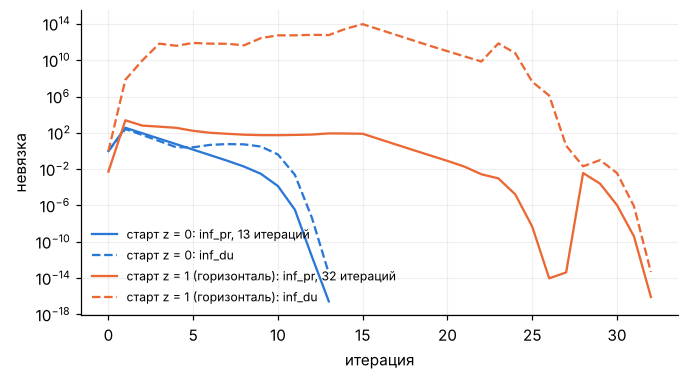

In [13]:
N = ch["N"]; t = np.linspace(-2, 2, N + 2)[1:-1]
fig, ax = plt.subplots(figsize=(7, 3.6))
for name, v0, col in (("старт z = 0", np.r_[t, np.zeros(N)], BLUE), ("старт z = 1 (горизонталь)", np.r_[t, np.ones(N)], ORANGE)):
    _, _, st = solve_rod_chain(ch, v0=v0)                              # IPOPT из двух стартов
    it = st["iterations"]
    ax.semilogy(np.maximum(it["inf_pr"], 1e-17), "-", color=col, label=f"{name}: inf_pr, {st['iter_count']} итераций")
    ax.semilogy(np.maximum(it["inf_du"], 1e-17), "--", color=col, label=f"{name}: inf_du")
ax.set_xlabel("итерация"); ax.set_ylabel("невязка"); ax.legend(fontsize=8); plt.show()

**Знак `lam_g`.** CasADi/IPOPT определяют функцию Лагранжа как $f+\lambda^\top g$, поэтому `sol["lam_g"]` $=-\lambda$ в соглашении конспекта ($L=f-\lambda^\top g$). Проверка: подставим оба знака в $\nabla f-J^\top\lambda$.

In [14]:
sol_lam_g = -lam                                                       # это то, что вернул IPOPT (solve_rod_chain меняет знак)
J = ca.Function("J", [ch["v"]], [ca.jacobian(ch["g"], ch["v"])])(v).full()
gf = ca.Function("gf", [ch["v"]], [ca.gradient(ch["f"], ch["v"])])(v).full().ravel()
print(f"|grad f - J^T lam|       = {np.linalg.norm(gf - J.T @ lam):.1e}   (наш знак — ноль)")
print(f"|grad f - J^T lam_g|     = {np.linalg.norm(gf - J.T @ sol_lam_g):.1e}   (знак IPOPT без поправки — не ноль)")
print(f"|grad f + J^T lam_g|     = {np.linalg.norm(gf + J.T @ sol_lam_g):.1e}   (L = f + lam_g^T g — ноль)")

|grad f - J^T lam|       = 1.2e-13   (наш знак — ноль)
|grad f - J^T lam_g|     = 1.2e+01   (знак IPOPT без поправки — не ноль)
|grad f + J^T lam_g|     = 1.2e-13   (L = f + lam_g^T g — ноль)


## Шпаргалка

| Что | Формула | Где в конспекте |
|---|---|---|
| касательное пространство | $T=\ker J(x^\ast)=\{p: J p=0\}$, $\dim T=n-m$ при LICQ | §2.2 |
| первый порядок | $\nabla_xL=\nabla f-J^\top\lambda=0$, $g=0$ — $n+m$ уравнений | §2.2 |
| LICQ | $\operatorname{rank}J(x^\ast)=m$; без него $\lambda$ может не быть (клюв) или быть много | §3 |
| второй порядок | $Z^\top\nabla^2_{xx}L\,Z\succ0$ — достаточно, $\succeq0$ — необходимо; $Z$ — базис $\ker J$ | §4.2 |
| множитель — цена | $\partial f^\ast/\partial b=\lambda^\ast$ для $g(x)=b$ | §5.2 |
| IPOPT | `lam_g` $=-\lambda$; `inf_pr` $=\lVert g\rVert_\infty$, `inf_du` $=\lVert\nabla_xL\rVert_\infty$ | §6 |

**Три вещи, которые легко перепутать.**

1. Кривизну проверяют у $L$, а не у $f$: член $-\lambda\nabla^2g$ — кривизна ограничений; у цепи на стержнях $\nabla^2f=0$, а минимум есть.
2. Знак $\lambda$ не говорит, минимум это или максимум (у окружности с $a=(0.3,0.1)$ в минимуме $\lambda>0$); говорит редуцированный гессиан.
3. `lam_g` у IPOPT — с противоположным знаком: $L_{\text{IPOPT}}=f+\lambda^\top g$.